In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the SMS Spam Collection dataset directly
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
df = pd.read_csv(url, sep='\t', header=None, names=['label', 'message'])

# Display the first 5 rows to make sure it loaded properly
print(df.head())

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [2]:
print(df['label'].value_counts())

label
ham     4825
spam     747
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, accuracy_score

# 1. Convert text labels into binary numbers (ham = 0, spam = 1)
df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})

# 2. Split data into Training set (80%) and Test set (20%)
X_train, X_test, y_train, y_test = train_test_split(
    df['message'], df['label_num'], test_size=0.2, random_state=42
)

# 3. Preprocess text and convert to numerical vectors using TF-IDF
vectorizer = TfidfVectorizer(stop_words='english', lowercase=True)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

# 4. Train the Multinomial Naive Bayes model
model = MultinomialNB()
model.fit(X_train_vec, y_train)

# 5. Make predictions on test set
y_pred = model.predict(X_test_vec)

# 6. Output model performance metrics
print("Accuracy Score:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy Score: 0.97847533632287

Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99       966
           1       1.00      0.84      0.91       149

    accuracy                           0.98      1115
   macro avg       0.99      0.92      0.95      1115
weighted avg       0.98      0.98      0.98      1115



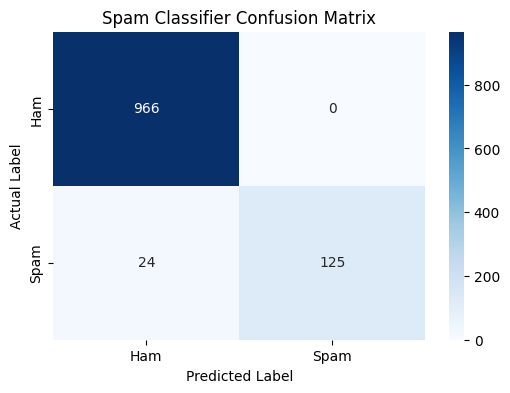

Test 1: Ham (Not Spam) ✅
Test 2: Ham (Not Spam) ✅


In [4]:
from sklearn.metrics import confusion_matrix

# 1. Generate and Save Confusion Matrix Graph
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.title('Spam Classifier Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

# Save the graph as a standalone png asset for GitHub
plt.savefig('confusion_matrix.png', bbox_inches='tight')
plt.show()

# 2. Interactive Prediction Function to test custom messages
def predict_message(text):
    text_vec = vectorizer.transform([text])
    prediction = model.predict(text_vec)
    return "Spam 🚨" if prediction[0] == 1 else "Ham (Not Spam) ✅"

# Test it with some examples
print("Test 1:", predict_message("Congratulations, you've won a free gift card! Click here."))
print("Test 2:", predict_message("Hey, are we still meeting for project discussion tomorrow?"))